In [1]:
%load_ext autoreload
%autoreload 2

from typing import Type, Tuple
from pathlib import Path
import logging
import pytorch_lightning as pl
from omegaconf import OmegaConf, DictConfig
from oat.predictor_module.oat_predictor import OATPredictor
from oat.data_module.setup import setup_data_and_transform
from matplotlib import pyplot as plt
import torch

def load_checkpoint(predictor_cls: Type[pl.LightningModule], checkpoint_file_path: str)-> Tuple[pl.LightningModule, DictConfig]:
    """
    Load and return the Predictor and its config from a checkpoint file.
    
    predictor_cls is the class of the Predictor to load. 
    checkpoint_file_path is the path to the checkpoint file, not the folder.
    It is expected that the parent folder of this checkpoint contains, at the same 
    level as the checkpoint, a yaml file with the config used to train the model.
    """
    path = Path(checkpoint_file_path)
    checkpoint_folder = path.parent
    config_path = checkpoint_folder / "config.yaml"
    
    cfg = OmegaConf.load(config_path)
    
    predictor = predictor_cls.load_from_checkpoint(path)
    
    return predictor, cfg

## Load model

In [ ]:

cfg_path = "/users/miccatta/s-ruc/observation_assimilation_transformer/checkpoints/debugging/precip_run_20260521_job4349797/best-model-epoch=20-val_loss=0.0949.ckpt"
predictor, cfg = load_checkpoint(OATPredictor, cfg_path)
predictor = predictor.eval()

/users/miccatta/s-ruc/observation_assimilation_transformer/.venv/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
/users/

## Load data

In [3]:
cfg.dataloader.test.batch_size = 4
cfg.dataloader.validation.batch_size = 4

In [172]:
logger = logging.getLogger(__name__)
dataset, num_train, train_loader, val_loader, test_loader, input_transform, output_transform = setup_data_and_transform(cfg, logger)

Dataset /scratch/mch/fzanetta/data/anemoi/datasets/mch-co1e-an-archive-0p01-2019-2024-1h-v1-pl13.zarr has missing dates
Gathering dataset statistics: 100%|██████████| 128/128 [00:52<00:00,  2.46it/s]


In [5]:
batch = next(iter(test_loader))
prediction = predictor.predict_step(batch, 0)

# Create query around station

In [6]:
batch_size = cfg.dataloader.validation.batch_size
station_idx = 4
center_pos = batch['query_data']['coords'][0, station_idx]
center_geo = batch['query_data']['geo'][0, station_idx]
size = 5000 # in metres
step = 50 # in metres
extent = [[center_pos[0] - size / 2, center_pos[0] + size / 2], 
          [center_pos[1] - size / 2, center_pos[1] + size / 2]]
mesh = torch.meshgrid(torch.linspace(extent[0][0], extent[0][1], size // step),
                      torch.linspace(extent[1][0], extent[1][1], size // step))
mesh = torch.stack(mesh, dim=-1)
mesh_shape = mesh.shape
mesh_flattened = mesh.view(-1, 2)

query_mesh = dataset.get_query(mesh_flattened)
query_batch = {k: v[None].expand(batch_size, -1, *v.shape[1:]) for k, v in query_mesh.items()}
print(val_loader.dataset.station_info['eval'].iloc[station_idx])

station_name                       Piz Martegnas
latitude                               46.577181
longitude                               9.529544
station_height                           2668.34
swiss_easting                     2760261.630627
swiss_northing                    1160569.205895
ASPECT_2000M_SIGRATIO1                 95.203278
WE_DERIVATIVE_2000M_SIGRATIO1          -0.076997
TPI_2000M                             197.632324
SN_DERIVATIVE_10000M_SIGRATIO1         -0.039819
dem                                  2653.903076
SN_DERIVATIVE_2000M_SIGRATIO1           0.007012
SLOPE_10000M_SIGRATIO1                  5.073856
ASPECT_10000M_SIGRATIO1                63.353928
SLOPE_2000M_SIGRATIO1                   4.421067
STD_2000M                              77.473644
STD_10000M                            348.342071
TPI_10000M                            458.242188
WE_DERIVATIVE_10000M_SIGRATIO1         -0.079358
station_type                       meteo_station
Name: PMA, dtype: ob

/users/miccatta/s-ruc/observation_assimilation_transformer/.venv/lib/python3.12/site-packages/torch/functional.py:513: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3609.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [ ]:
batch['query_data'] = query_batch
predictor.model.num_samples = 100
prediction_dict = predictor.predict_step(batch, 0, return_as='distribution')

The returned distributions are still parameterized in the transformed space. Ensure to apply the appropriate inverse transform to the distribution parameters before using them.


In [18]:
prediction = predictor.predict_step(batch, 0, return_as='samples')

In [21]:
predictor.output_var_names

['precipitation']

# Plot predictions

In [173]:
batch_iter = iter(test_loader)


In [179]:
for i in range(1000):
    batch = next(batch_iter)
    mean_prec = batch['global_data']['global_field'][0,0].mean()
    
    if mean_prec > 0.0007:
        break

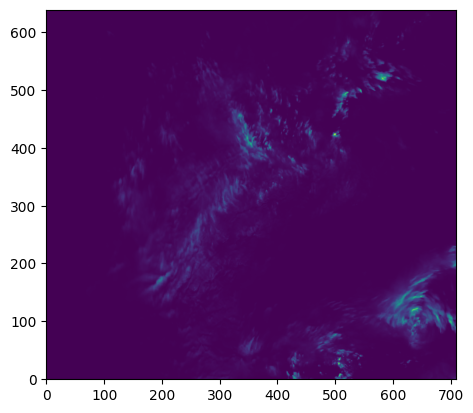

In [181]:
plt.imshow(batch['global_data']['global_field'][0,0], origin='lower')

In [184]:
batch['query_data'] = query_batch
predictor.model.num_samples = 100
prediction_dict = predictor.predict_step(batch, 0, return_as='distribution')
prediction = predictor.predict_step(batch, 0, return_as='samples')

The returned distributions are still parameterized in the transformed space. Ensure to apply the appropriate inverse transform to the distribution parameters before using them.


In [189]:
prediction.mean(dim=-2).reshape(batch_size, *mesh_shape[:-1]).shape

torch.Size([4, 100, 100])

In [207]:
batch['global_data']['global_field'][:,0].shape

torch.Size([4, 640, 710])

In [217]:
batch['query_data']['coords'].shape

torch.Size([4, 10000, 2])

In [226]:
batch['index']

tensor([600, 601, 602, 603])

In [ ]:
import xarray as xr
import numpy as np
import torch

def extract_nwp_at_coords( # TODO CHECK THIS, Claude-generated, not tested
    global_field: torch.Tensor,   # (B, C, H, W)
    coords: torch.Tensor,          # (B, N_q, 2)  [easting, northing]
    ref_ds: xr.Dataset,
) -> np.ndarray:                   # (B, N_q, C)
    field = global_field.numpy()
    coords_np = coords.numpy()
    B, C, H, W = field.shape
    N_q = coords_np.shape[1]
    out = np.empty((B, N_q, C), dtype=field.dtype)

    x_coords = ref_ds.x.values
    y_coords = ref_ds.y.values

    for b in range(B):
        da = xr.DataArray(field[b], dims=['c', 'y', 'x'],
                          coords={'x': x_coords, 'y': y_coords})
        x_q = xr.DataArray(coords_np[b, :, 0], dims='points')
        y_q = xr.DataArray(coords_np[b, :, 1], dims='points')
        out[b] = da.sel(x=x_q, y=y_q, method='nearest').values.T  # (N_q, C)

    return out


nwp_at_queries = extract_nwp_at_coords(
    batch['global_data']['global_field'],
    batch['query_data']['coords'],
    dataset.ref_nwp_ds,
)

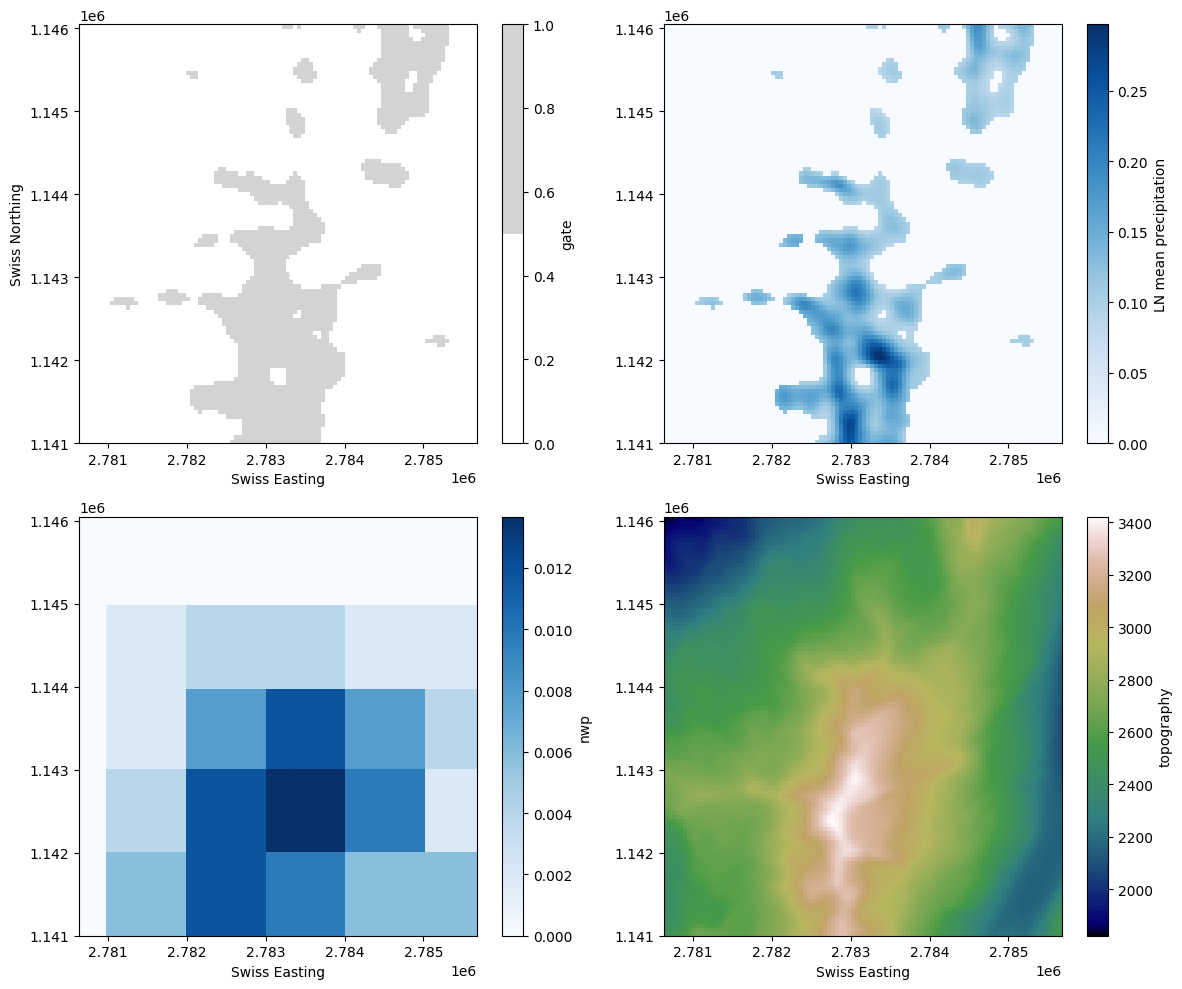

In [ ]:
# tensor([600, 601, 602, 603]) Figure obtained with this batch['index']

# TODO the reshaping and indexing is a bit hacky and messy. Improve later

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
std_pred_mesh = prediction.detach().std(dim=-2).cpu().numpy().reshape(batch_size, *mesh_shape[:-1])

var_idx = 0

batch_idx = 2

ax1 = axes[0, 0]
ax2 = axes[0, 1]
ax3 = axes[1, 0]
ax4 = axes[1, 1]


gate_threshold = 0.2

# Thesholded ZILN gate 

gate = prediction_dict['precipitation'].gate.reshape(batch_size, *mesh_shape[:-1]).cpu().detach().numpy()
im1 = ax1.pcolor(mesh[:, :, 0], mesh[:, :, 1], (1.0 - gate[batch_idx, :, :]) > gate_threshold, shading='auto', cmap=plt.cm.colors.ListedColormap(['white', 'lightgray']))
plt.colorbar(im1, ax=ax1, label=f"gate")
ax1.set_xlabel("Swiss Easting")
ax1.set_ylabel("Swiss Northing")


# mean_precip = prediction.mean(dim=-2).reshape(batch_size, *mesh_shape[:-1])

def mean_of_ln(loc, scale):
    return torch.exp(loc + 0.5 * scale ** 2)

# Mean of the LN part of the ZILN

mean_ln = mean_of_ln(prediction_dict['precipitation'].loc, prediction_dict['precipitation'].scale)
mean_ln = (1.0 - prediction_dict['precipitation'].gate) * mean_ln  # Scale by gate

mean_ln = mean_ln[batch_idx].reshape(mesh_shape[:-1]).detach().numpy()
masked_ln = mean_ln.copy()
masked_ln[(1.0 - gate[batch_idx, :, :]) < gate_threshold] = 0.0
 
# im2 = ax2.pcolor(mesh[:, :, 0], mesh[:, :, 1], mean_precip[batch_idx, :, :], shading='auto')
im2 = ax2.pcolor(mesh[:, :, 0], mesh[:, :, 1], masked_ln, shading='auto', cmap='Blues')
# plt.colorbar(im2, ax=ax2, label=f"mean {predictor.output_var_names[var_idx]}")
plt.colorbar(im2, ax=ax2, label=f"LN mean {predictor.output_var_names[var_idx]}")
ax2.set_xlabel("Swiss Easting")

# The NWP closest value to the query points

nwp = nwp_at_queries[...,0].reshape(batch_size, *mesh_shape[:-1])
im3 = ax3.pcolor(mesh[:, :, 0], mesh[:, :, 1], nwp[batch_idx] * 1000, shading='auto', cmap='Blues')
plt.colorbar(im3, ax=ax3, label=f"nwp")
ax3.set_xlabel("Swiss Easting")

# The topography at the query points. I take the middle point of the topo patch, which is 32x32

topo = batch['query_data']['topo'][..., 0, 16, 16].reshape(batch_size, *mesh_shape[:-1]) # TODO might be a stupid way to get it. Im taking the middle point of [32,32]
nwp = nwp_at_queries[...,0].reshape(batch_size, *mesh_shape[:-1])
im4 = ax4.pcolor(mesh[:, :, 0], mesh[:, :, 1], topo[batch_idx], shading='auto', cmap='gist_earth')
plt.colorbar(im4, ax=ax4, label=f"topography")
ax4.set_xlabel("Swiss Easting")

plt.tight_layout()
